<a href="https://colab.research.google.com/github/sofiaduartea/telecom-analysis/blob/main/Telecom_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage =pd.read_csv('/datasets/usage.csv') #completa el código

In [ ]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print()
# Proporción de valores nulos)
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print()
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
**Respuesta:**  En el dataset users hay dos columnas con valores faltantes: city (11.72%) y churn_date (88.35%), respectivamente. En el dataset usage, la columna date tiene la menor proporción de nulos (0.125%), mientras que duration y length presentan proporciones mucho mayores: 55.19% y 44.74% respectivamente.
- Indica qué harías: ¿imputar, eliminar, ignorar?
**Respuesta:**  En users, churn_date se ignora porque los nulos indican usuarios activos, y city se imputa con “Unknown” para conservar las filas sin inventar datos.
En usage, los nulos de duration y length son estructurales: duration solo se registra para las llamadas (call) y length solo para los mensajes de texto (text). Por eso se ignoran y cada columna se analiza únicamente dentro de su tipo de registro. De los datos de la columna date, se eliminan sus pocas filas nulas (0.125%) por ser una proporción insignificante.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
print(users.describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` va desde 10000 a 13999 con 4000 registros, y se observa que no hay valores sospechosos, pues su media y mediana coinciden, siendo 11999.50, lo que es normal en una secuencia uniforme.
- La columna `age` va desde -999 a 79 con 4000 registros, en lo cual se observa que presenta un sentinel (-999), pues es imposible para una edad. Esto distorsiona la media (33.7, menor que la mediana de 47) y la desviación estándar (123.2).

In [ ]:
# explorar columnas numéricas de usage
print(usage.describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas id y user_id tienen 40000 registros entre 4000 usuarios, y se observa que no tienen valores sospechosos, pues su resumen estadístico está acorde para la info que se tiene.
- Las columnas duration y length tienen un mínimo de 0. En duration, el 0 puede indicar llamada no contestada, y se evidencia que el valor máximo (120) está muy por encima del percentil 75% (6.99), por lo cual se considera un valor atípico. La columna length también tiene un mínimo de 0, poco lógico para un mensaje, y un máximo de 1490, muy superior al percentil 75 (64), lo que sugiere valores extremos.

In [ ]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(col)
    print(users[col].value_counts(dropna=False))
    print()
    print(users[col].value_counts(normalize=True))
    print()



city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Bogotá      0.228830
CDMX        0.206740
Medellín    0.174455
GDL         0.127443
Cali        0.120079
MTY         0.115265
?           0.027188
Name: city, dtype: float64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64



- En la columna city se ve cómo el 2.71% de los datos no tienen información respecto a la ciudad.
- En la columna plan se evidencia que toda la información está completa.

In [ ]:

# explorar columna categórica de usage
columnas_usage = ['type'] # completa el código

for col in columnas_usage:
    print(col)
    print(usage[col].value_counts(dropna=False))
    print()
    print(usage[col].value_counts(normalize=True))
    print()


type
text    22092
call    17908
Name: type, dtype: int64

text    0.5523
call    0.4477
Name: type, dtype: float64



- En la columna `type` tambien se evidencia que los casillas de esta columna estan completas.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

**Respuesta:**
En el dataset users se encontró que en la columna age el valor mínimo es -999, lo cual es imposible para una edad, por lo que se considera un sentinel. Asimismo, en la columna city aparece el símbolo “?” en el 2.71% de los registros, que funciona como placeholder de un valor desconocido. Asi mismo, la columna en la columna city el 2,71% de los datos no tienen una ciudad especifica sino que estan asignados como '?'

En el dataset usage se encontraron valores sospechosos en columnas duration y length. En duration, el valor minimo es 0 y que el valor máximo (120) está muy por encima del percentil 75% (6.99), por lo cual se considera un valor atípico. La columna length también tiene un valor mínimo de 0, lo cual no es lógico para un mensaje, y un máximo de 1490, muy superior al percentil 75 (64), lo que sugiere valores extremos.
  
- ¿Qué acción tomarías?

**Respuesta:**
En age, reemplazaría el -999 por nulo (NaN) para que no distorsione los cálculos, y luego evaluaría imputar con la mediana.
En city, reemplazaría “?” por nulo y lo unificaría con los demás desconocidos bajo la categoría “Unknown”.
En duration y length, conservaría los valores máximos (120 y 1490) porque son atípicos pero posibles, y revisaría los ceros: en duration pueden representar llamadas no contestadas, mientras que en length un mensaje vacío no es lógico, por lo que reemplazaría esos ceros por nulo si son pocos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors="coerce", utc=True)# completa el código

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors="coerce", utc=True)## completa el código

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, se encuentra info de los años 2022, 2023, 2024 y 2026. Pero el año 2024 es el que más datos tiene (1330)

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts().sort_index())

2024.0    39950
Name: date, dtype: int64


En `date`, se evidencian 39950 registros para el unico año presente en esta tabla, el 2024

Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

**Respuesta:** Sí. En el dataset users, la columna reg_date presenta 40 registros (1% del total) con año 2026, lo cual es imposible porque los datos se registraron hasta 2024. Los demás años (2022, 2023 y 2024) tienen una distribución uniforme, con alrededor de 1300 registros cada uno.

- ¿Qué harías con ellas?

**Respuesta:**
  Reemplazaría las fechas de 2026 por nulo (NaT), ya que son errores de captura y no se puede conocer la fecha real. Así conservo el resto de la información de cada usuario sin distorsionar los análisis temporales.
  En usage no se requiere ninguna acción sobre años fuera de rango, porque no hay ninguno.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
print((users['city'] == '?').sum())

0


In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts().sort_index())
print()
print("cantidad de NA:", users['reg_date'].isna().sum())

2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64

cantidad de NA: 40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')['duration'].count())

type
call    17908
text       16
Name: duration, dtype: int64


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].count())

type
call       12
text    22092
Name: length, dtype: int64


Los valores nulos en 'duration' y 'length' son de tipo MAR porque los nulos dependen de otra columna observada (type), no del propio valor faltante. Con ello se confirma el patron, pues de los pocos datos cruzados, son excepciones minimas, menos del 0.1% que pueden ser errores de captura, pero no cambian la conclusion

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoria.

In [ ]:
# Resumen estadístico de las columnas numéricas
cols_num = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_num].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  

- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

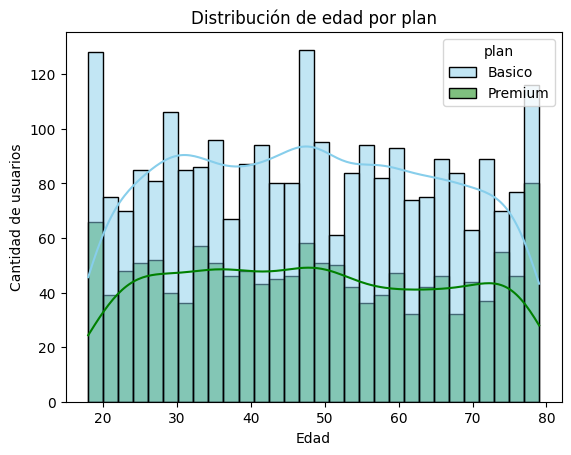

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x="age", hue="plan", palette=["skyblue", "green"], bins=30, kde=True)
plt.title("Distribución de edad por plan")
plt.xlabel("Edad")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights:
- La distribución de age es aproximadamente uniforme, sin sesgo marcado. Ambos planes se reparten de forma similar en todo el rango, por lo que no existe un patrón entre plan y edad.

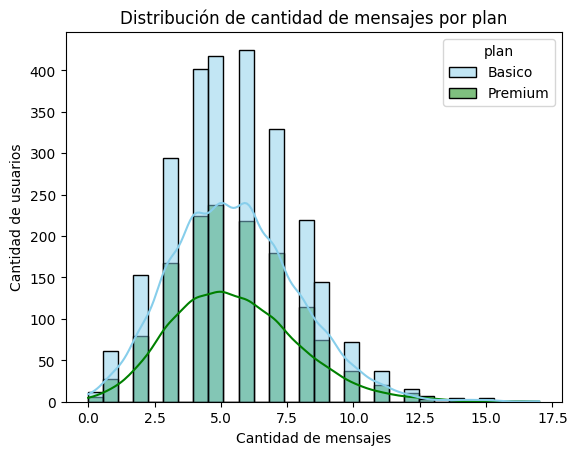

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue", "green"], bins=30, kde=True)
plt.title("Distribución de cantidad de mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights:
- La distribución de cant_mensajes está sesgada a la derecha: la mayoría envía entre 3 y 7 mensajes y pocos superan los 10. Ambos planes se centran alrededor de 5 mensajes, por lo que no existe un patrón claro entre plan y mensajes.

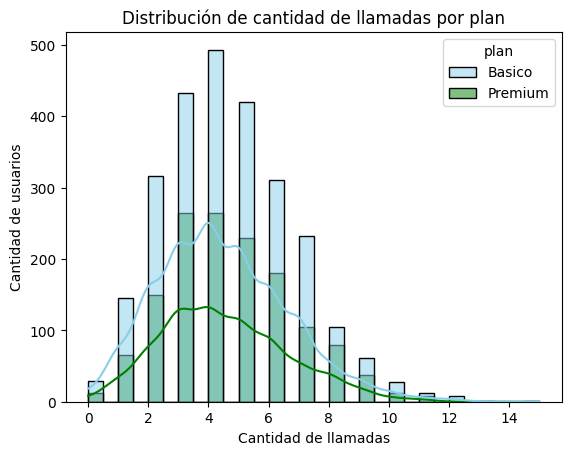

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue", "green"], bins=30, kde=True)
plt.title("Distribución de cantidad de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights:
- La distribución de cant_llamadas está sesgada a la derecha: la mayoría hace entre 2 y 6 llamadas, con un pico cerca de 4, y pocos usuarios llegan a 10 o más. Básico y Premium se comportan de manera similar, así que no existe un patrón claro.

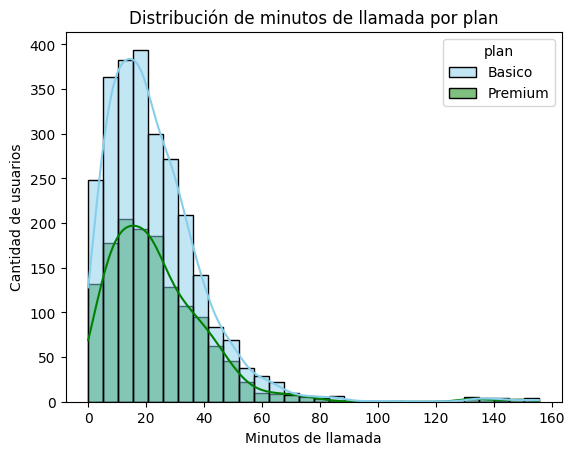

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue", "green"], bins=30,  kde=True)
plt.title("Distribución de minutos de llamada por plan")
plt.xlabel("Minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights:
- La distribución de cant_minutos_llamada está fuertemente sesgada a la derecha: la mayoría acumula menos de 50 minutos, con un pico cerca de 15-20, y unos pocos usuarios superan los 100 minutos (posibles outliers). Ambos planes tienen una distribución similar, por lo que no existe un patrón claro entre plan y minutos.

Los usuarios Básico tienden a hacer alrededor de 4 llamadas y enviar alrededor de 5 mensajes, igual que los Premium. No existe algún patrón de uso diferente entre planes.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

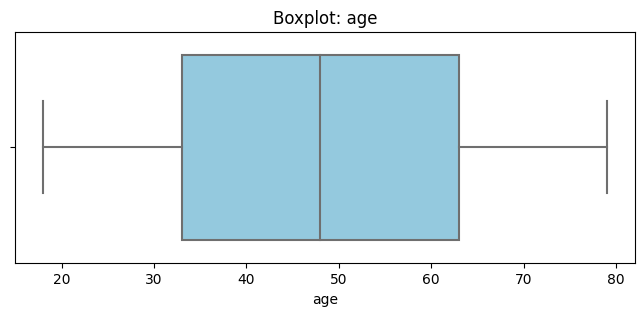

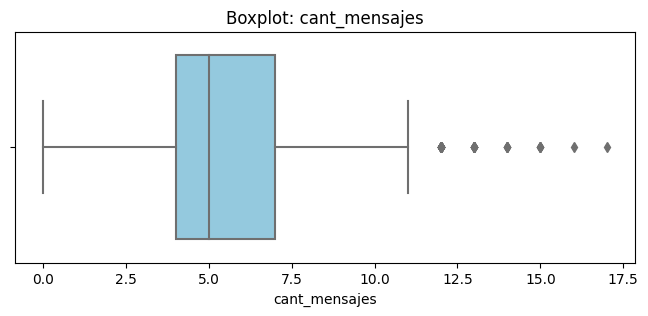

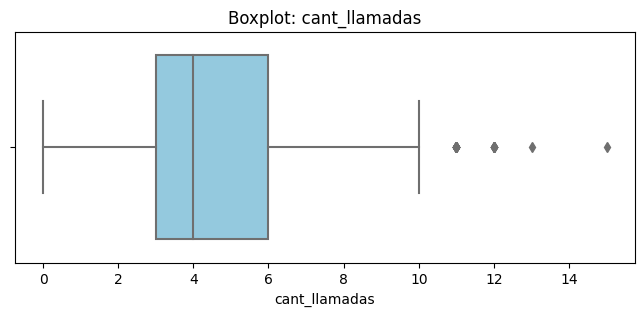

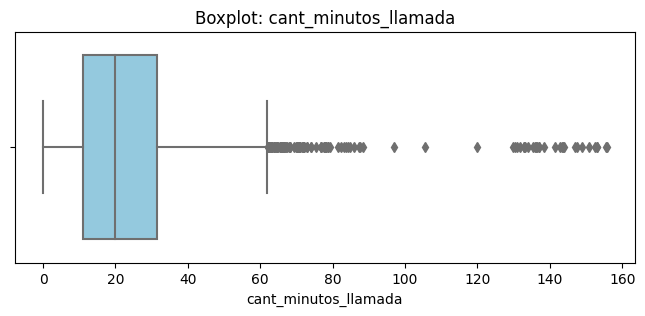

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=user_profile, x=col, color="skyblue")
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: No presenta outliers. Los valores van de 18 a 79 años y no aparece ningún punto fuera de los bigotes del boxplot.
- cant_mensajes: Presenta outliers únicamente del lado derecho, con valores de 12 a 17 mensajes. Son usuarios que envían más mensajes de lo habitual, ya que la mayoría se concentra entre 4 y 7.
- cant_llamadas: Presenta outliers únicamente del lado derecho, con valores de 11 a 15 llamadas. La mayoría de los usuarios hace entre 3 y 6 llamadas.
- cant_minutos_llamada: Presenta outliers únicamente del lado derecho, con valores desde aproximadamente 60 hasta cerca de 155 minutos. Es la variable con más puntos fuera de los bigotes, y se observa un grupo separado entre 130 y 155 minutos, correspondiente a usuarios con un uso de llamadas muy alto.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    n_inferior = (user_profile[col] < limite_inferior).sum()
    n_superior = (user_profile[col] > limite_superior).sum()

    print(f"{col}:")
    print(f"  Límite inferior: {limite_inferior:.2f} ({n_inferior} outliers)")
    print(f"  Límite superior: {limite_superior:.2f} ({n_superior} outliers)")
    print()


age:
  Límite inferior: -12.00 (0 outliers)
  Límite superior: 108.00 (0 outliers)

cant_mensajes:
  Límite inferior: -0.50 (0 outliers)
  Límite superior: 11.50 (46 outliers)

cant_llamadas:
  Límite inferior: -1.50 (0 outliers)
  Límite superior: 10.50 (30 outliers)

cant_minutos_llamada:
  Límite inferior: -19.32 (0 outliers)
  Límite superior: 61.86 (109 outliers)



In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights:
**Respuesta:**
Age no presenta outliers. En cant_mensajes, cant_llamadas y cant_minutos_llamada sí existen, todos del lado superior (46, 30 y 109 usuarios respectivamente), con límites superiores de 11.5, 10.5 y 61.86. Decidí conservarlos porque son valores posibles que representan usuarios de uso intensivo y no errores de captura; sus máximos (17 mensajes, 15 llamadas y 155.69 minutos) son razonables. Al resumir estas variables usaré la mediana, que es menos sensible a valores extremos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
def clasificar_uso(fila):
    if fila["cant_llamadas"] < 5 and fila["cant_mensajes"] < 5:
        return "Bajo uso"
    elif fila["cant_llamadas"] < 10 and fila["cant_mensajes"] < 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile["grupo_uso"] = user_profile.apply(clasificar_uso, axis=1)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def clasificar_edad(edad):
    if edad < 30:
        return "Joven"
    elif edad < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile["grupo_edad"] = user_profile["age"].apply(clasificar_edad)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

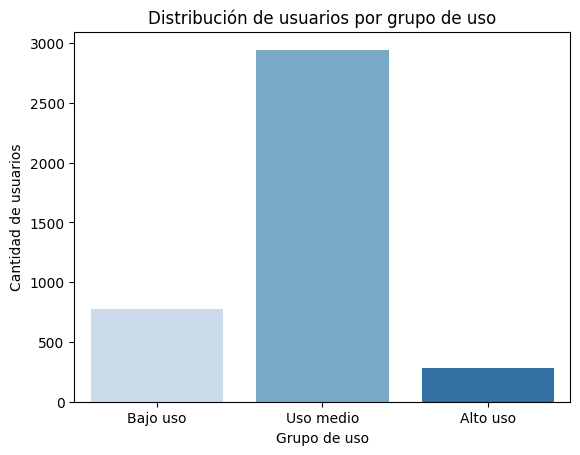

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso",
              order=["Bajo uso", "Uso medio", "Alto uso"],
              palette="Blues")
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

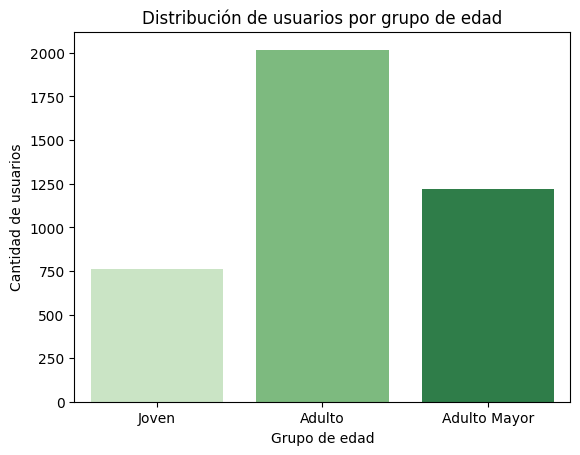

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad",
              order=["Joven", "Adulto", "Adulto Mayor"],
              palette="Greens")
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()

In [ ]:
print(user_profile["grupo_edad"].value_counts())
print()
print(user_profile["grupo_edad"].value_counts(normalize=True) * 100)

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64


In [ ]:
print(user_profile["grupo_uso"].value_counts())
print()
print(user_profile["grupo_uso"].value_counts(normalize=True) * 100)

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

Uso medio    73.575
Bajo uso     19.450
Alto uso      6.975
Name: grupo_uso, dtype: float64



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- *Valores centinela en 'age':* se encontraron valores de -999 (imposibles para una edad). Se reemplazaron con la mediana para no distorsionar la media ni la desviación estándar.
- *Placeholder en 'city':* el 2.71% de los registros tenía “?” como ciudad. Se convirtió en nulo, y la columna además tenía un 11.72% de nulos originales, por lo que cerca del 14% de las ciudades es desconocido.
- *Fechas imposibles en 'reg_date':* 40 usuarios (1%) tenían fecha de registro en 2026, cuando los datos llegan hasta 2024. Se marcaron como nulas por ser errores de captura.
- *Nulos en 'usage':* date tenía 50 registros nulos (0.125%). duration y length tienen nulos porque dependen de type (MAR): duration aplica a llamadas y length a mensajes. Se dejaron como nulos.
- Outliers en variables de uso: cant_mensajes (46 usuarios), cant_llamadas (30) y cant_minutos_llamada (109), todos del lado superior. Se conservaron por ser valores posibles de usuarios de uso intensivo.


🔍 **Segmentos por Edad**

El grupo más grande es Adulto (30 a 59 años), con cerca de la mitad de los usuarios. Le sigue Adulto Mayor con aproximadamente 1230 usuarios y el más pequeño es Joven. Esto es coherente con que las edades se distribuyen de forma casi uniforme entre 18 y 79: el grupo Adulto abarca un rango más amplio (30 años) que Joven (12 años) y Adulto Mayor (20 años), por eso concentra más usuarios.


📊 **Segmentos por Nivel de Uso**

La gran mayoría de los usuarios (72%) está en Uso medio. Bajo uso reúne a cerca del 19% y Alto uso es el grupo más pequeño, con menos del 10%, con aproximadamente 40 usuarios. Esto concuerda con las distribuciones sesgadas a la derecha: la mayoría tiene un uso moderado (medianas de 5 mensajes y 4 llamadas) y pocos usuarios tienen un uso intensivo.

➡️ Esto sugiere que la base de clientes se compone principalmente de adultos con un uso moderado del servicio, y que los usuarios de uso intensivo son una minoría. Además, las distribuciones de edad y uso se comportan de forma similar en los planes Básico y Premium, por lo que el plan no parece explicar las diferencias en el comportamiento.


💡 **Recomendaciones**
- *Corregir la captura de datos en el origen.* El 1% de las fechas de registro tenía año 2026, el 2.71% de las ciudades era “?” y la edad usaba -999 como código de “desconocido”. Estos errores sugieren que no hay validación en el formulario ni en la carga. Acción: restringir fechas a rangos válidos, hacer obligatoria la edad y la ciudad (o usar un campo explícito de “prefiero no decir”) y auditar mensualmente el porcentaje de nulos y centinelas por columna.
  
- *Rediseñar la oferta del segmento Adulto con Uso medio.* Es el grupo dominante (≈50% por edad y ≈72% por uso). Acción: crear paquetes pensados para un perfil de ~5 mensajes y ~4 llamadas por usuario, y medir retención y migración al plan Premium frente a un grupo de control.

- *Activar a los usuarios de Bajo uso (≈19%).* Su actividad es mínima, por lo que son los más propensos a abandonar sin que se note. Acción: campañas de reactivación (bonos de minutos o mensajes por alcanzar cierto uso) y seguimiento de cuántos pasan a Uso medio en 60 o 90 días.

- *Proteger al segmento de Alto uso (<10%).* Son pocos, pero generan el mayor consumo (hasta ~155 minutos y 17 mensajes). Acción: ofrecerles beneficios de fidelización, atención prioritaria o un plan a medida, y tratarlos como candidatos naturales al plan Premium.

- *Replantear la diferencia entre Básico y Premium.* Los histogramas mostraron que ambos planes se comportan igual en edad, mensajes, llamadas y minutos. Si Premium no se traduce en un uso distinto, el cliente podría no percibir su valor. Acción: revisar qué incluye cada plan, probar cambios en precios o beneficios y evaluar si Premium se justifica para quienes tienen uso intensivo.

- *Profundizar el análisis antes de decidir.* Con estos datos no se sabe cuántos usuarios abandonan ni por qué. Acción: usar churn_date para comparar la tasa de baja entre segmentos (edad y uso) y priorizar las campañas donde el abandono sea mayor.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`